# Análise do Viés de Gênero em Algoritmos de Recrutamento e Seleção
### Um Estudo Comparativo entre Modelos de Inteligência Artificial — Bases Reais do Kaggle

**Trabalho de Conclusão de Curso em Ciência de Dados – TCC530**
Universidade Virtual do Estado de São Paulo (UNIVESP) — Turma 005
Orientador: Anderson Nogueira Cotrim

**Grupo:** Clausinei Ferreira, Iza Melão, Renan Silva Pinheiro,  Stefany Gracy Barros Da Silva

---

## Sobre o notebook

Este notebook **mapeia explicitamente** as colunas de cada base, com base na inspeção real já realizada:

| Base | Arquivo | Linhas | Colunas | Gênero | Alvo |
|---|---|---|---|---|---|
| Principal (Jangir) | `Dataset.csv` | 2.000 | 6 | `gender` | `shortlisted` |
| Validação (Utrecht) | `recruitmentdataset-2022-1.3.csv` | 4.000 | 15 | `gender` | `decision` |

> **Nota sobre o tamanho real da base de validação:** a inspeção mostrou que o *Utrecht Fairness Recruitment Dataset* contém, na verdade, **4.000 registros** (não ~500, como constava na citação inicial do artigo — esse número já foi corrigido no documento do TCC). O pacote do Kaggle também inclui um segundo arquivo, `2025-fairness-recruitment-dataset.csv`, com nomenclatura de colunas voltada explicitamente a *fairness* (ex.: `Gender(feature,sensitive)`), que pode ser explorado como extensão futura, mas não é utilizado nesta versão para manter a comparação com o arquivo já documentado na literatura.

Toda a lógica do *pipeline* (pré-processamento → treino → avaliação → auditoria de justiça → explicabilidade → mitigação) foi organizada em **uma única função reutilizável**, chamada uma vez para cada base — isso elimina a duplicação de código do notebook original e evita o tipo de erro em cascata.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

## 1. Configuração do Ambiente

In [1]:
!pip install -q fairlearn shap kagglehub

In [2]:
import os
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, ConfusionMatrixDisplay
)

from fairlearn.metrics import (
    MetricFrame, demographic_parity_difference, equalized_odds_difference,
    selection_rate, true_positive_rate
)
from fairlearn.reductions import ExponentiatedGradient, DemographicParity

import shap

SEED = 42
np.random.seed(SEED)
sns.set_theme(style="whitegrid")

print("Ambiente configurado com sucesso.")

Ambiente configurado com sucesso.


## 2. Download das Bases Reais (Kaggle)

In [3]:
import kagglehub

path_principal = kagglehub.dataset_download(
    "rahuljangir78/recruitment-bias-and-fairness-ai-dataset"
)
path_utrecht = kagglehub.dataset_download(
    "ictinstitute/utrecht-fairness-recruitment-dataset"
)

print("Base principal (Jangir):", path_principal)
print("Base de validação (Utrecht):", path_utrecht)

100%|██████████| 27.1k/27.1k [00:00<00:00, 16.4MB/s]

Extracting files...


100%|██████████| 46.1k/46.1k [00:00<00:00, 21.7MB/s]

Extracting files...
Base principal (Jangir): /root/.cache/kagglehub/datasets/rahuljangir78/recruitment-bias-and-fairness-ai-dataset/versions/1
Base de validação (Utrecht): /root/.cache/kagglehub/datasets/ictinstitute/utrecht-fairness-recruitment-dataset/versions/4


In [4]:
ARQUIVO_PRINCIPAL = os.path.join(path_principal, "Dataset.csv")
ARQUIVO_UTRECHT = os.path.join(path_utrecht, "recruitmentdataset-2022-1.3.csv")

df_principal_raw = pd.read_csv(ARQUIVO_PRINCIPAL)
df_utrecht_raw = pd.read_csv(ARQUIVO_UTRECHT)

print("Base principal:", df_principal_raw.shape)
display(df_principal_raw.head())

print("\nBase Utrecht:", df_utrecht_raw.shape)
display(df_utrecht_raw.head())

Base principal: (2000, 6)


,gender,age,education_level,experience_years,screening_score,shortlisted
0,Male,35,Masters,1,72.473130,0
1,Female,32,Bachelors,15,55.004084,0
2,Male,36,Masters,19,60.156004,0
3,Male,44,Bachelors,6,75.846397,0
4,Male,39,High School,1,43.297540,1



Base Utrecht: (4000, 15)


,Id,gender,age,nationality,sport,ind-university_grade,ind-debateclub,ind-programming_exp,ind-international_exp,ind-entrepeneur_exp,ind-languages,ind-exact_study,ind-degree,company,decision
0,x8011e,female,24,German,Swimming,70,False,False,False,False,1,True,phd,A,True
1,x6077a,male,26,German,Golf,67,False,True,False,False,2,True,bachelor,A,False
2,x6006e,female,23,Dutch,Running,67,False,True,True,False,0,True,master,A,False
3,x2173b,male,24,Dutch,Cricket,70,False,True,False,False,1,True,master,A,True
4,x6241a,female,26,German,Golf,59,False,False,False,False,1,False,master,A,True


## 3. Mapeamento Explícito das Colunas

Aqui **não há detecção automática**: o mapeamento de cada base foi definido manualmente, a partir da inspeção da estrutura real de cada arquivo.

In [5]:
MAPEAMENTO = {
    "Jangir (principal)": {
        "df": df_principal_raw,
        "gender_col": "gender",
        "target_col": "shortlisted",
        "drop_cols": [],
    },
    "Utrecht (validação cruzada)": {
        "df": df_utrecht_raw,
        "gender_col": "gender",
        "target_col": "decision",
        "drop_cols": ["Id"],
    },
}

for nome, cfg in MAPEAMENTO.items():
    print(f"{nome}: gênero='{cfg['gender_col']}' | alvo='{cfg['target_col']}' | shape={cfg['df'].shape}")
    print("  Valores do alvo:", cfg["df"][cfg["target_col"]].unique()[:5])
    print("  Valores de gênero:", cfg["df"][cfg["gender_col"]].unique()[:5])

Jangir (principal): gênero='gender' | alvo='shortlisted' | shape=(2000, 6)
  Valores do alvo: [0 1]
  Valores de gênero: ['Male' 'Female']
Utrecht (validação cruzada): gênero='gender' | alvo='decision' | shape=(4000, 15)
  Valores do alvo: [ True False]
  Valores de gênero: ['female' 'male' 'other']


## 4. Funções do Pipeline (reutilizadas para as duas bases)

A função `para_binario` padroniza a variável-alvo (que pode vir como booleano, `0`/`1` ou texto) em um formato único. A função `calcular_pesos_reweighing` implementa a fórmula de Kamiran e Calders (2012), já usada na Parte II da pesquisa. A função `rodar_pipeline_completo` executa, para uma base qualquer, todas as etapas descritas na Metodologia do artigo (itens 3.3 e 3.4).

In [6]:
def para_binario(serie):
    """Padroniza a variavel-alvo (bool, 0/1 ou texto) em 0/1 explicito."""
    if serie.dtype == bool:
        return serie.astype(int)
    if pd.api.types.is_numeric_dtype(serie):
        return serie.astype(int)
    positivos = {"1", "true", "yes", "y", "sim", "hired", "selected", "accepted", "aprovado", "contratado"}
    return serie.astype(str).str.strip().str.lower().isin(positivos).astype(int)


def calcular_pesos_reweighing(dataframe, coluna_sensivel, coluna_rotulo):
    """Formula de Kamiran e Calders (2012): W(g, y) = [P(g) * P(y)] / P(g, y)"""
    n_total = len(dataframe)
    pesos = pd.Series(index=dataframe.index, dtype=float)
    for grupo in dataframe[coluna_sensivel].unique():
        for rotulo in dataframe[coluna_rotulo].unique():
            mascara = (dataframe[coluna_sensivel] == grupo) & (dataframe[coluna_rotulo] == rotulo)
            n_gr = mascara.sum()
            if n_gr == 0:
                continue
            p_g = (dataframe[coluna_sensivel] == grupo).mean()
            p_y = (dataframe[coluna_rotulo] == rotulo).mean()
            p_gy = n_gr / n_total
            pesos.loc[mascara] = (p_g * p_y) / p_gy
    return pesos


def montar_preprocessador(X_train):
    cat_cols = X_train.select_dtypes(include=["object", "category", "bool"]).columns.tolist()
    num_cols = X_train.select_dtypes(include=[np.number]).columns.tolist()
    prep = ColumnTransformer([
        ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
        ("num", StandardScaler(), num_cols),
    ])
    return prep, cat_cols, num_cols

In [7]:
def rodar_pipeline_completo(df_raw, gender_col, target_col, drop_cols=None, nome_base=""):
    """Executa o pipeline metodologico completo (itens 3.1 a 3.4 do artigo) para uma base.
    Retorna um dicionario com todas as tabelas de resultado geradas.
    """
    drop_cols = drop_cols or []
    df = df_raw.drop(columns=drop_cols, errors="ignore").copy()
    df = df.dropna(subset=[gender_col, target_col]).copy()
    df["_target"] = para_binario(df[target_col])
    df = df.drop(columns=[target_col])

    X = df.drop(columns=["_target"])
    y = df["_target"]
    sensitive = df[gender_col]

    X_train, X_test, y_train, y_test, sf_train, sf_test = train_test_split(
        X, y, sensitive, test_size=0.25, stratify=y, random_state=SEED
    )
    prep, cat_cols, num_cols = montar_preprocessador(X_train)

    modelos = {
        "Regressao Logistica": LogisticRegression(max_iter=2000, random_state=SEED),
        "Regressao Logistica (balanceada)": LogisticRegression(max_iter=2000, random_state=SEED, class_weight="balanced"),
        "Random Forest": RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1),
    }

    pipelines, linhas_desempenho, linhas_fairness = {}, [], []
    for nome, clf in modelos.items():
        pipe = Pipeline([("prep", prep), ("clf", clf)])
        pipe.fit(X_train, y_train)
        pipelines[nome] = pipe

        y_pred = pipe.predict(X_test)
        y_proba = pipe.predict_proba(X_test)[:, 1]

        linhas_desempenho.append({
            "base": nome_base, "modelo": nome,
            "acuracia": accuracy_score(y_test, y_pred),
            "precisao": precision_score(y_test, y_pred, zero_division=0),
            "recall": recall_score(y_test, y_pred, zero_division=0),
            "f1_score": f1_score(y_test, y_pred, zero_division=0),
            "roc_auc": roc_auc_score(y_test, y_proba),
        })

        linhas_fairness.append({
            "base": nome_base, "modelo": nome,
            "dp_diff": demographic_parity_difference(y_test, y_pred, sensitive_features=sf_test),
            "eo_diff": equalized_odds_difference(y_test, y_pred, sensitive_features=sf_test),
        })

    # --- Explicabilidade (SHAP) no Random Forest ---
    rf_pipe = pipelines["Random Forest"]
    X_test_prep = rf_pipe.named_steps["prep"].transform(X_test)
    X_test_prep = X_test_prep.toarray() if hasattr(X_test_prep, "toarray") else X_test_prep
    feat_names = rf_pipe.named_steps["prep"].get_feature_names_out()
    X_test_shap = pd.DataFrame(X_test_prep, columns=feat_names)

    explainer = shap.TreeExplainer(rf_pipe.named_steps["clf"])
    shap_values = explainer.shap_values(X_test_shap)
    if isinstance(shap_values, list):
        shap_valores_classe1 = shap_values[1]
    elif hasattr(shap_values, "ndim") and shap_values.ndim == 3:
        shap_valores_classe1 = shap_values[:, :, 1]
    else:
        shap_valores_classe1 = shap_values

    # --- Reweighing (pre-processamento) ---
    pesos = calcular_pesos_reweighing(df.assign(**{gender_col: sensitive}), gender_col, "_target")
    w_train = pesos.loc[X_train.index]
    X_train_prep = prep.fit_transform(X_train)
    X_test_prep2 = prep.transform(X_test)

    linhas_reweighing = []
    for nome, ModeloClasse, kwargs in [
        ("Regressao Logistica", LogisticRegression, {"max_iter": 2000, "random_state": SEED}),
        ("Random Forest", RandomForestClassifier, {"n_estimators": 300, "random_state": SEED, "n_jobs": -1}),
    ]:
        m_base = ModeloClasse(**kwargs)
        m_base.fit(X_train_prep, y_train)
        m_rw = ModeloClasse(**kwargs)
        m_rw.fit(X_train_prep, y_train, sample_weight=w_train.values)

        dp_antes = demographic_parity_difference(y_test, m_base.predict(X_test_prep2), sensitive_features=sf_test)
        dp_depois = demographic_parity_difference(y_test, m_rw.predict(X_test_prep2), sensitive_features=sf_test)
        acc_antes = accuracy_score(y_test, m_base.predict(X_test_prep2))
        acc_depois = accuracy_score(y_test, m_rw.predict(X_test_prep2))

        linhas_reweighing.append({
            "base": nome_base, "modelo": nome,
            "acuracia_antes": acc_antes, "acuracia_depois": acc_depois,
            "dp_diff_antes": dp_antes, "dp_diff_depois": dp_depois,
        })

    # --- ExponentiatedGradient (em-processamento) ---
    # O ExponentiatedGradient e estocastico (usa um classificador aleatorizado).
    # Por isso, repetimos o treinamento com varias sementes e reportamos a media e o
    # desvio padrao, em vez de confiar em uma unica execucao.
    SEEDS_EG = [42, 7, 123, 2024, 99]
    dp_eg_lista, acc_eg_lista = [], []
    for seed_eg in SEEDS_EG:
        eg = ExponentiatedGradient(
            estimator=RandomForestClassifier(n_estimators=300, random_state=seed_eg, n_jobs=-1),
            constraints=DemographicParity(),
        )
        eg.fit(X_train_prep, y_train, sensitive_features=sf_train)
        y_pred_eg = eg.predict(X_test_prep2)
        dp_eg_lista.append(demographic_parity_difference(y_test, y_pred_eg, sensitive_features=sf_test))
        acc_eg_lista.append(accuracy_score(y_test, y_pred_eg))

    linha_eg = pd.DataFrame([{
        "base": nome_base, "modelo": "Random Forest",
        "acuracia_apos_eg_media": np.mean(acc_eg_lista), "acuracia_apos_eg_dp": np.std(acc_eg_lista),
        "dp_diff_apos_eg_media": np.mean(dp_eg_lista), "dp_diff_apos_eg_dp": np.std(dp_eg_lista),
        "n_execucoes": len(SEEDS_EG),
    }])

    return {
        "nome_base": nome_base,
        "shape_original": df_raw.shape,
        "cat_cols": cat_cols, "num_cols": num_cols,
        "pipelines": pipelines,
        "desempenho": pd.DataFrame(linhas_desempenho),
        "fairness": pd.DataFrame(linhas_fairness),
        "reweighing": pd.DataFrame(linhas_reweighing),
        "exponentiated_gradient": linha_eg,
        "shap_values": shap_valores_classe1,
        "X_test_shap": X_test_shap,
    }

### 4.1 Balanceamento de Classes e de Grupos Sensíveis

Antes de interpretar qualquer métrica de desempenho ou de *fairness*, é essencial verificar dois pontos: (1) se a variável-alvo está balanceada — um forte desbalanceamento pode levar um classificador a simplesmente prever sempre a classe majoritária; e (2) o tamanho de cada subgrupo sensível — um subgrupo muito pequeno (por exemplo, a categoria `other` em gênero) torna as métricas de *fairness* estatisticamente instáveis, pois poucas amostras erradas já mudam bastante a taxa calculada para aquele grupo.

In [8]:
for nome_base, cfg in MAPEAMENTO.items():
    df_tmp = cfg["df"]
    print(f"=== {nome_base} ===")
    print("Distribuição do alvo (%):")
    print((para_binario(df_tmp[cfg["target_col"]]).value_counts(normalize=True) * 100).round(1))
    print("\nTamanho de cada grupo sensível:")
    print(df_tmp[cfg["gender_col"]].value_counts())
    print()

=== Jangir (principal) ===
Distribuição do alvo (%):
shortlisted
0    59.8
1    40.2
Name: proportion, dtype: float64

Tamanho de cada grupo sensível:
gender
Male      1016
Female     984
Name: count, dtype: int64

=== Utrecht (validação cruzada) ===
Distribuição do alvo (%):
decision
0    68.3
1    31.7
Name: proportion, dtype: float64

Tamanho de cada grupo sensível:
gender
male      2127
female    1790
other       83
Name: count, dtype: int64



## 5. Execução do Pipeline nas Duas Bases

A mesma função é chamada uma vez para cada base, evitando duplicação de código e garantindo que ambas passem exatamente pelas mesmas etapas — condição necessária para que a comparação cruzada entre bases (item 3.2 do artigo) seja metodologicamente válida.

In [9]:
resultados = {}
for nome_base, cfg in MAPEAMENTO.items():
    resultados[nome_base] = rodar_pipeline_completo(
        df_raw=cfg["df"],
        gender_col=cfg["gender_col"],
        target_col=cfg["target_col"],
        drop_cols=cfg["drop_cols"],
        nome_base=nome_base,
    )

print("Pipeline executado com sucesso para:", list(resultados.keys()))

Pipeline executado com sucesso para: ['Jangir (principal)', 'Utrecht (validação cruzada)']


## 6. Desempenho Preditivo — Comparação entre Bases e Modelos

In [10]:
tabela_desempenho = pd.concat([r["desempenho"] for r in resultados.values()], ignore_index=True)
tabela_desempenho.round(3)

,base,modelo,acuracia,precisao,recall,f1_score,roc_auc
0,Jangir (principal),Regressao Logistica,0.598,0.000,0.000,0.000,0.492
1,Jangir (principal),Regressao Logistica (balanceada),0.482,0.382,0.468,0.421,0.492
2,Jangir (principal),Random Forest,0.524,0.382,0.299,0.335,0.509
3,Utrecht (validação cruzada),Regressao Logistica,0.740,0.627,0.445,0.520,0.792
4,Utrecht (validação cruzada),Regressao Logistica (balanceada),0.705,0.525,0.735,0.612,0.791
5,Utrecht (validação cruzada),Random Forest,0.857,0.802,0.729,0.764,0.927


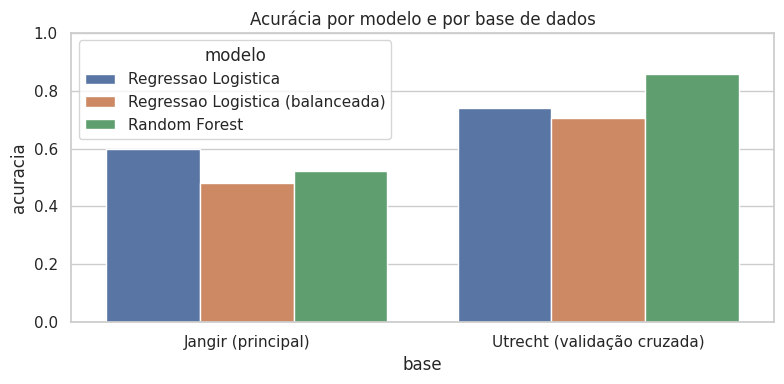

In [11]:
fig, ax = plt.subplots(figsize=(8, 4))
sns.barplot(data=tabela_desempenho, x="base", y="acuracia", hue="modelo", ax=ax)
ax.set_title("Acurácia por modelo e por base de dados")
ax.set_ylim(0, 1)
plt.tight_layout()
plt.show()

## 7. Auditoria de Justiça Algorítmica — Comparação entre Bases

In [12]:
tabela_fairness = pd.concat([r["fairness"] for r in resultados.values()], ignore_index=True)
tabela_fairness.round(3)

,base,modelo,dp_diff,eo_diff
0,Jangir (principal),Regressao Logistica,0.000,0.000
1,Jangir (principal),Regressao Logistica (balanceada),0.952,0.989
2,Jangir (principal),Random Forest,0.086,0.093
3,Utrecht (validação cruzada),Regressao Logistica,0.169,0.387
4,Utrecht (validação cruzada),Regressao Logistica (balanceada),0.197,0.312
5,Utrecht (validação cruzada),Random Forest,0.207,0.344


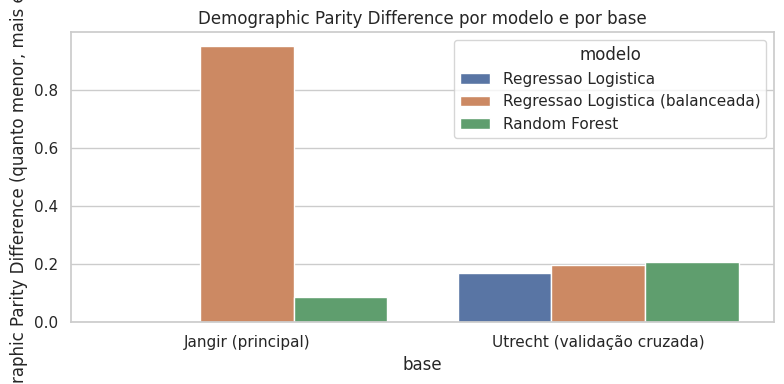

In [13]:
fig, ax = plt.subplots(figsize=(8, 4))
sns.barplot(data=tabela_fairness, x="base", y="dp_diff", hue="modelo", ax=ax)
ax.set_title("Demographic Parity Difference por modelo e por base")
ax.set_ylabel("Demographic Parity Difference (quanto menor, mais equitativo)")
plt.tight_layout()
plt.show()

## 8. Explicabilidade (SHAP) — Base Principal

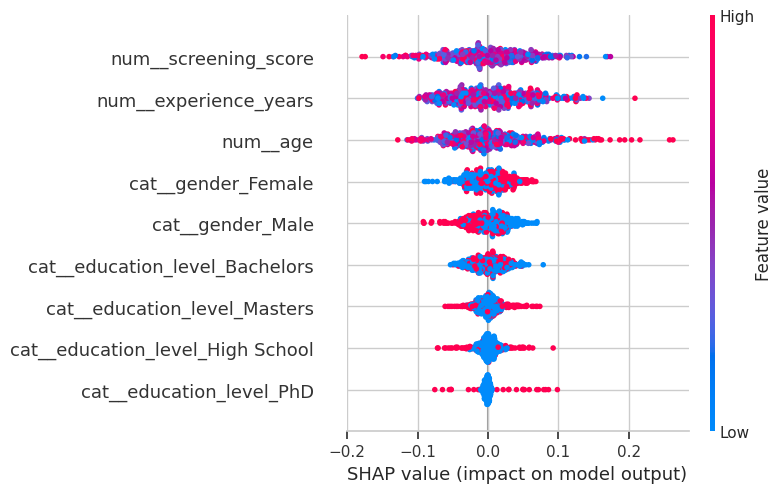

In [14]:
shap.summary_plot(
    resultados["Jangir (principal)"]["shap_values"],
    resultados["Jangir (principal)"]["X_test_shap"],
    show=True,
)

## 9. Mitigação de Viés — Reweighing (Pré-processamento)

In [15]:
tabela_reweighing = pd.concat([r["reweighing"] for r in resultados.values()], ignore_index=True)
tabela_reweighing.round(3)

,base,modelo,acuracia_antes,acuracia_depois,dp_diff_antes,dp_diff_depois
0,Jangir (principal),Regressao Logistica,0.598,0.598,0.000,0.000
1,Jangir (principal),Random Forest,0.524,0.544,0.086,0.077
2,Utrecht (validação cruzada),Regressao Logistica,0.740,0.740,0.169,0.100
3,Utrecht (validação cruzada),Random Forest,0.857,0.864,0.207,0.163


## 10. Mitigação de Viés — ExponentiatedGradient (Em-processamento)

> **Ajuste em relação à versão anterior:** como o `ExponentiatedGradient` treina um classificador aleatorizado, uma única execução pode não representar bem seu comportamento esperado. A célula abaixo agora roda o algoritmo com 5 sementes diferentes e reporta média ± desvio-padrão de acurácia e de *Demographic Parity Difference*.

In [16]:
tabela_eg = pd.concat([r["exponentiated_gradient"] for r in resultados.values()], ignore_index=True)
tabela_eg.round(3)

,base,modelo,acuracia_apos_eg_media,acuracia_apos_eg_dp,dp_diff_apos_eg_media,dp_diff_apos_eg_dp,n_execucoes
0,Jangir (principal),Random Forest,0.545,0.004,0.056,0.017,5
1,Utrecht (validação cruzada),Random Forest,0.826,0.006,0.195,0.018,5


## 11. Síntese Comparativa Final

A tabela abaixo reúne, lado a lado, o efeito das duas famílias de mitigação (Reweighing e ExponentiatedGradient) sobre o Random Forest, em cada uma das duas bases — a comparação central da pesquisa.

In [17]:
sintese = tabela_reweighing[tabela_reweighing["modelo"] == "Random Forest"][
    ["base", "dp_diff_antes", "dp_diff_depois"]
].rename(columns={"dp_diff_depois": "dp_diff_apos_reweighing"})

sintese = sintese.merge(
    tabela_eg[["base", "dp_diff_apos_eg_media", "dp_diff_apos_eg_dp"]], on="base"
)

sintese.round(3)

,base,dp_diff_antes,dp_diff_apos_reweighing,dp_diff_apos_eg_media,dp_diff_apos_eg_dp
0,Jangir (principal),0.086,0.077,0.056,0.017
1,Utrecht (validação cruzada),0.207,0.163,0.195,0.018


## 11.1 Teste da Hipótese de Proxy: Remover o Gênero das Features Resolve o Viés?

A hipótese da pesquisa é que a simples remoção do atributo de gênero **não é suficiente** para eliminar disparidades, pois outras variáveis podem atuar como *proxies* (Parte introdução do artigo). Para testar isso diretamente, a função abaixo repete o treinamento do Random Forest **sem o gênero como variável preditora** — mas mantendo o gênero apenas para *auditar* a justiça do resultado — e compara o Demographic Parity Difference com o cenário em que o gênero permanece como feature.

In [18]:
def testar_cenario_sem_genero(df_raw, gender_col, target_col, drop_cols=None, nome_base=""):
    """Repete o treinamento do Random Forest sem o genero como feature preditora,
    mantendo-o apenas como atributo sensivel para auditoria de fairness."""
    drop_cols = drop_cols or []
    df = df_raw.drop(columns=drop_cols, errors="ignore").copy()
    df = df.dropna(subset=[gender_col, target_col]).copy()
    df["_target"] = para_binario(df[target_col])
    df = df.drop(columns=[target_col])

    X = df.drop(columns=["_target"])
    y = df["_target"]
    sensitive = df[gender_col]
    X_sem_genero = X.drop(columns=[gender_col])

    Xtr, Xte, ytr, yte, sftr, sfte = train_test_split(
        X_sem_genero, y, sensitive, test_size=0.25, stratify=y, random_state=SEED
    )
    prep, _, _ = montar_preprocessador(Xtr)
    Xtr_prep = prep.fit_transform(Xtr)
    Xte_prep = prep.transform(Xte)

    modelo = RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1)
    modelo.fit(Xtr_prep, ytr)
    y_pred = modelo.predict(Xte_prep)

    return {
        "base": nome_base,
        "acuracia_sem_genero": accuracy_score(yte, y_pred),
        "dp_diff_sem_genero": demographic_parity_difference(yte, y_pred, sensitive_features=sfte),
    }


linhas_sem_genero = []
for nome_base, cfg in MAPEAMENTO.items():
    linhas_sem_genero.append(
        testar_cenario_sem_genero(
            df_raw=cfg["df"], gender_col=cfg["gender_col"], target_col=cfg["target_col"],
            drop_cols=cfg["drop_cols"], nome_base=nome_base,
        )
    )

tabela_sem_genero = pd.DataFrame(linhas_sem_genero)

# Compara com o Random Forest original (COM genero como feature)
comparacao_proxy = tabela_fairness[tabela_fairness["modelo"] == "Random Forest"][["base", "dp_diff"]].rename(
    columns={"dp_diff": "dp_diff_com_genero"}
).merge(tabela_sem_genero, on="base")

comparacao_proxy.round(3)

,base,dp_diff_com_genero,acuracia_sem_genero,dp_diff_sem_genero
0,Jangir (principal),0.086,0.566,0.039
1,Utrecht (validação cruzada),0.207,0.857,0.155


**Como interpretar esta tabela:** se `dp_diff_sem_genero` continuar próximo de `dp_diff_com_genero` (em vez de cair para perto de zero), isso é evidência empírica de que outras variáveis da base estão atuando como *proxies* de gênero — confirmando a hipótese discutida na Introdução e na Metodologia (item 3.2) do artigo. Se, ao contrário, a diferença cair de forma acentuada, isso sugere que o gênero era, naquela base, a principal fonte direta de disparidade.

## 11.2 Proporção de positivos por gênero e métricas por grupo

Esta seção complementa a auditoria de justiça: (a) mostra a proporção de candidatos positivos por gênero nas bases originais, antes de qualquer modelo, e (b) mostra a taxa de seleção, a taxa de verdadeiros positivos (TPR) e a taxa de falsos positivos (FPR) por gênero no conjunto de teste, para cada modelo. Assim é possível ver quais grupos estão sendo favorecidos ou prejudicados.

In [19]:
os.makedirs("/content/resultados_tcc", exist_ok=True)
from fairlearn.metrics import MetricFrame, selection_rate, true_positive_rate, false_positive_rate

# (a) Proporção de positivos por gênero nas bases originais, antes de qualquer modelo
partes = []
for nome_base, cfg in MAPEAMENTO.items():
    d = cfg["df"].dropna(subset=[cfg["gender_col"], cfg["target_col"]]).copy()
    d["_alvo"] = para_binario(d[cfg["target_col"]])
    t = d.groupby(cfg["gender_col"])["_alvo"].agg(
        registros="size", positivos="sum", taxa_positivos="mean"
    ).reset_index().rename(columns={cfg["gender_col"]: "genero"})
    t.insert(0, "base", nome_base)
    partes.append(t)
tabela_dados_genero = pd.concat(partes, ignore_index=True)
display(tabela_dados_genero.round(3))

# (b) Taxa de seleção, TPR e FPR por gênero no conjunto de teste, para cada modelo
partes = []
for nome_base, cfg in MAPEAMENTO.items():
    d = cfg["df"].drop(columns=cfg["drop_cols"], errors="ignore").dropna(
        subset=[cfg["gender_col"], cfg["target_col"]]).copy()
    d["_target"] = para_binario(d[cfg["target_col"]])
    d = d.drop(columns=[cfg["target_col"]])
    X, y, sens = d.drop(columns=["_target"]), d["_target"], d[cfg["gender_col"]]
    _, X_test, _, y_test, _, sf_test = train_test_split(
        X, y, sens, test_size=0.25, stratify=y, random_state=SEED
    )
    for nome_modelo, pipe in resultados[nome_base]["pipelines"].items():
        y_pred = pipe.predict(X_test)
        mf = MetricFrame(
            metrics={"taxa_selecao": selection_rate, "tpr": true_positive_rate, "fpr": false_positive_rate},
            y_true=y_test, y_pred=y_pred, sensitive_features=sf_test,
        )
        t = mf.by_group.reset_index().rename(columns={cfg["gender_col"]: "genero"})
        t["n_teste"] = t["genero"].map(sf_test.value_counts())
        t["taxa_positivos_real_teste"] = t["genero"].map(y_test.groupby(sf_test).mean())
        t.insert(0, "modelo", nome_modelo)
        t.insert(0, "base", nome_base)
        partes.append(t)
tabela_por_genero = pd.concat(partes, ignore_index=True)
display(tabela_por_genero.round(3))

tabela_dados_genero.to_csv("/content/resultados_tcc/dados_por_genero.csv", index=False)
tabela_por_genero.to_csv("/content/resultados_tcc/metricas_por_genero.csv", index=False)

,base,genero,registros,positivos,taxa_positivos
0,Jangir (principal),Female,984,414,0.421
1,Jangir (principal),Male,1016,391,0.385
2,Utrecht (validação cruzada),female,1790,492,0.275
3,Utrecht (validação cruzada),male,2127,750,0.353
4,Utrecht (validação cruzada),other,83,25,0.301


,base,modelo,genero,taxa_selecao,tpr,fpr,n_teste,taxa_positivos_real_teste
0,Jangir (principal),Regressao Logistica,Female,0.000,0.000,0.000,246,0.386
1,Jangir (principal),Regressao Logistica,Male,0.000,0.000,0.000,254,0.417
2,Jangir (principal),Regressao Logistica (balanceada),Female,0.976,0.989,0.967,246,0.386
3,Jangir (principal),Regressao Logistica (balanceada),Male,0.024,0.000,0.041,254,0.417
4,Jangir (principal),Random Forest,Female,0.358,0.347,0.364,246,0.386
5,Jangir (principal),Random Forest,Male,0.272,0.255,0.284,254,0.417
6,Utrecht (validação cruzada),Regressao Logistica,female,0.135,0.280,0.081,459,0.272
7,Utrecht (validação cruzada),Regressao Logistica,male,0.304,0.550,0.164,519,0.364
8,Utrecht (validação cruzada),Regressao Logistica,other,0.227,0.667,0.158,22,0.136
9,Utrecht (validação cruzada),Regressao Logistica (balanceada),female,0.349,0.688,0.222,459,0.272


## 11.3 Figura SHAP com rótulos em português

Gera a figura de importância global das variáveis (Random Forest, base Jangir) com rótulos em português e a exporta em PNG.

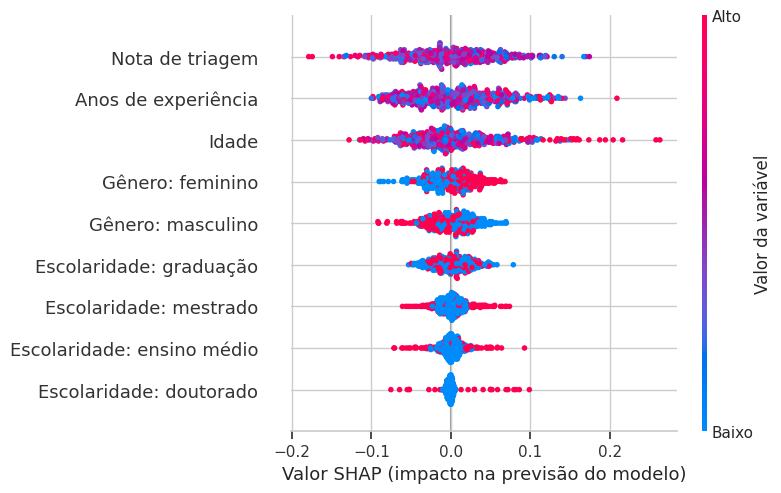

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [20]:
rotulos = {
    "num__screening_score": "Nota de triagem",
    "num__experience_years": "Anos de experiência",
    "num__age": "Idade",
    "cat__gender_Female": "Gênero: feminino",
    "cat__gender_Male": "Gênero: masculino",
    "cat__education_level_Bachelors": "Escolaridade: graduação",
    "cat__education_level_Masters": "Escolaridade: mestrado",
    "cat__education_level_High School": "Escolaridade: ensino médio",
    "cat__education_level_PhD": "Escolaridade: doutorado",
}
r = resultados["Jangir (principal)"]
X_rot = r["X_test_shap"].rename(columns=rotulos)

shap.summary_plot(r["shap_values"], X_rot, show=False)
fig = plt.gcf()
fig.axes[0].set_xlabel("Valor SHAP (impacto na previsão do modelo)")
try:
    fig.axes[-1].set_ylabel("Valor da variável")
    fig.axes[-1].set_yticklabels(["Baixo", "Alto"])
except Exception:
    pass
fig.savefig("/content/resultados_tcc/figura_shap.png", dpi=300, bbox_inches="tight")
plt.show()

from google.colab import files
files.download("/content/resultados_tcc/figura_shap.png")

## 12. Exportação dos Resultados

Os CSVs abaixo podem ser usados diretamente para montar as tabelas da seção de Resultados do artigo.

In [21]:
os.makedirs("/content/resultados_tcc", exist_ok=True)

tabela_desempenho.to_csv("/content/resultados_tcc/desempenho_modelos.csv", index=False)
tabela_fairness.to_csv("/content/resultados_tcc/fairness_modelos.csv", index=False)
tabela_reweighing.to_csv("/content/resultados_tcc/reweighing.csv", index=False)
tabela_eg.to_csv("/content/resultados_tcc/exponentiated_gradient.csv", index=False)
sintese.to_csv("/content/resultados_tcc/sintese_comparativa.csv", index=False)
comparacao_proxy.to_csv("/content/resultados_tcc/teste_hipotese_proxy.csv", index=False)

print("Arquivos salvos em /content/resultados_tcc/")
print(os.listdir("/content/resultados_tcc"))

Arquivos salvos em /content/resultados_tcc/
['sintese_comparativa.csv', 'reweighing.csv', 'dados_por_genero.csv', 'figura_shap.png', 'metricas_por_genero.csv', 'desempenho_modelos.csv', 'fairness_modelos.csv', 'teste_hipotese_proxy.csv', 'exponentiated_gradient.csv']
